# CMB ANISOTROPIES
### From the first light to the angular power spectrum

**Daniel Baumann, *Cosmology* · Chapters 3, 6 & 7**  
**Observations:** ESA/Planck Collaboration · **Planck 2018 Legacy Release (PR3)**

---

**Learning objectives**

1. Understand the dimensionless temperature anisotropy $\Theta(\hat{\boldsymbol n})$.
2. Inspect the genuine 2018 ESA/Planck all-sky CMB visualization.
3. Define the spherical-harmonic coefficients $a_{\ell m}$ and the angular power spectrum $C_\ell$.
4. Plot the **published Planck 2018 TT bandpowers, uncertainties, and best-fit $\Lambda$CDM bandpowers**.
5. Identify acoustic peaks and explain the connection to primordial scalar perturbations.

> **Data integrity:** The measured TT values are included *inside this notebook* as a transcription of the official PR3 binned text file. No random or synthetic observation is generated. The ESA sky map below is a **published colour visualization**, not a numeric HEALPix FITS map; its RGB pixels must not be interpreted as calibrated $\mu\mathrm K$ measurements.

## 1 · Background: what is $\Theta$?

We decompose the sky temperature into its all-sky mean and a small directional fluctuation:

$$
\boxed{T(\hat{\boldsymbol n})=\bar T_0+\delta T(\hat{\boldsymbol n})},
\qquad \bar T_0\simeq 2.7255\,\mathrm K.
$$

The **dimensionless temperature anisotropy** is

$$
\boxed{\Theta(\hat{\boldsymbol n})\equiv\frac{\delta T(\hat{\boldsymbol n})}{\bar T_0}
=\frac{T(\hat{\boldsymbol n})-\bar T_0}{\bar T_0}}.
$$

After subtracting the dominant kinematic dipole and foregrounds, cosmological fluctuations are typically of order

$$
\boxed{\Theta\sim10^{-5}},\qquad
\delta T\sim 2.7255\times10^{-5}\,\mathrm K \sim27\,\mu\mathrm K.
$$

Here $\hat{\boldsymbol n}$ is a direction on the celestial sphere. The brightness pattern is related to conditions at last scattering ($z_\ast\sim1100$) and to gravity and motion along the line of sight.

**Important distinction:** locally in a blackbody photon fluid, $\delta_\gamma=4\delta T/\bar T$, but the *observed* $\Theta$ also includes gravitational Sachs–Wolfe, Doppler and integrated Sachs–Wolfe contributions.

## 2 · Figure 1 — Observed Planck temperature anisotropy sky

![ESA/Planck 2018 full-sky CMB colour visualization](https://www.esa.int/var/esa/storage/images/esa_multimedia/images/2018/07/planck_s_view_of_the_cosmic_microwave_background2/17601832-1-eng-GB/Planck_s_view_of_the_cosmic_microwave_background.jpg)

*Credit:* **ESA / Planck Collaboration (2018)**. The original image is [hosted by ESA](https://www.esa.int/ESA_Multimedia/Images/2018/07/Planck_s_view_of_the_cosmic_microwave_background2). It displays the actual measured anisotropy pattern after component separation, rendered with a colour palette. The image requires an internet connection when first displayed.

**Physics:** red/orange patches are relatively warmer and blue patches relatively cooler. The colours are visually enhanced to reveal variations around the 2.7255 K mean; they do **not** imply large changes in absolute temperature.

> For numerical pixel analysis or a calibrated colour bar, use the official Planck **SMICA HEALPix FITS intensity map** (large, ~hundreds of MB) instead of sampling this JPEG. This notebook deliberately keeps the original visual product intact.

## 3 · From the sky map to $C_\ell$

Spherical harmonics are the Fourier basis of the sphere. Expand the dimensionless field as

$$
\boxed{\Theta(\hat{\boldsymbol n}) = \sum_{\ell=0}^{\infty}\sum_{m=-\ell}^{\ell}a_{\ell m}Y_{\ell m}(\hat{\boldsymbol n})}.
$$

Orthogonality gives the coefficients:

$$
\boxed{a_{\ell m}=\int_{4\pi}d\Omega\,\Theta(\hat{\boldsymbol n})Y_{\ell m}^{\ast}(\hat{\boldsymbol n})}.
$$

For a statistically isotropic ensemble:

$$
\boxed{\langle a_{\ell m}a_{\ell'm'}^*\rangle=C_\ell^{\Theta\Theta}\,\delta_{\ell\ell'}\delta_{mm'}}.
$$

On an ideal, full, noiseless sky we estimate:

$$
\boxed{\widehat C_\ell^{\Theta\Theta}=\frac{1}{2\ell+1}\sum_{m=-\ell}^{\ell}|a_{\ell m}|^2}.
$$

**$\ell$ represents angular scale**, roughly $\theta\sim180^\circ/\ell$: low $\ell$ = large sky features; high $\ell$ = small features. The displayed $C_\ell^{\Theta\Theta}$ is *dimensionless*, since $\Theta$ is dimensionless.

### The actual quantity plotted by Planck

The public TT file contains bandpowers $D_\ell$ in **$\mu\mathrm K^2$**. These correspond to the dimensional temperature spectrum (not the dimensionless $C_\ell^{\Theta\Theta}$):

$$
\boxed{D_\ell^{TT}\equiv\frac{\ell(\ell+1)}{2\pi}C_\ell^{TT}},
\qquad
\boxed{C_\ell^{TT}=\bar T_0^{\,2}\,C_\ell^{\Theta\Theta}}.
$$

When $\bar T_0$ is inserted in microkelvin, $C_\ell^{TT}$ and $D_\ell^{TT}$ are in $\mu\mathrm K^2$. **Do not multiply the released Planck $D_\ell$ by $\ell(\ell+1)/(2\pi)$ again!**

In [1]:
# 1. Scientific environment — Python 3 kernel (SageMath not required)
import io
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Math

plt.rcParams.update({
    "figure.figsize": (11, 5.7),
    "figure.dpi": 120,
    "savefig.dpi": 180,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.titleweight": "semibold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.20,
})
C_NAVY = "#173753"
C_BLUE = "#247BA0"
C_GOLD = "#D39D32"
C_DARK = "#263447"
C_RED = "#AF4A49"

T_CMB_K = 2.7255
print("Scientific libraries imported successfully.")

Scientific libraries imported successfully.


## 4 · Genuine Planck 2018 TT bandpowers

**Official source:** [NASA/IPAC IRSA — Planck PR3 TT binned text file](https://irsa.ipac.caltech.edu/data/Planck/release_3/ancillary-data/cosmoparams/COM_PowerSpect_CMB-TT-binned_R3.01.txt)

**Dataset:** `COM_PowerSpect_CMB-TT-binned_R3.01.txt` (Planck 2018 release). The original file provides five columns:

$$
\ell_{\mathrm{bin}},\quad D_\ell^{TT},\quad -\sigma(D_\ell),\quad +\sigma(D_\ell),\quad D_{\ell,\,\mathrm{best\ fit}}^{TT}.
$$

In this release the tabulated upper and lower uncertainties are identical, so we include one common $1\sigma$ value. These are **83 published binned measurements**, approximately $47\lesssim\ell\lesssim2499$. The smooth connected model line in the following figure joins published best-fit bandpowers at bin centres; it is not a new theoretical Boltzmann-code calculation.

In [4]:
# 2. OFFICIAL observational data — embedded to work without network access.
# Columns: effective ell | D_ell [microK^2] | symmetric 1-sigma error | best-fit D_ell
DATA = r'''
47.711224 1479.33552 50.7654876 1461.11304
76.4716065 2034.96833 54.7101576 2062.38073
105.917385 2955.39416 64.9766440 2904.52526
135.605348 3869.51392 76.9143744 3902.48963
165.405597 4889.46506 86.5856259 4861.35537
195.266870 5464.10945 90.5533459 5534.80715
225.164945 5793.43954 87.1348811 5726.93135
255.086908 5372.88375 76.9383697 5374.98113
285.025248 4627.67753 62.5199141 4588.32266
314.975304 3604.23851 47.1589439 3596.89801
344.934027 2631.20029 33.8762191 2667.45188
374.899344 2033.05943 24.8190562 2018.16864
404.869791 1753.36253 20.7109083 1748.34025
434.844309 1787.57901 20.6713695 1821.92489
464.822111 2162.04649 22.7523861 2098.23728
494.802601 2422.08480 24.9726104 2397.72998
524.785320 2573.48050 25.9184118 2571.44487
554.769905 2546.29768 25.0510538 2551.80645
584.756069 2360.64530 22.7209283 2364.36140
614.743583 2095.43505 19.8505454 2104.80607
644.732258 1884.67698 17.5024864 1890.96016
674.721939 1813.16288 16.4306044 1812.52216
704.712498 1883.19393 16.7990643 1896.72650
734.703827 2097.13072 18.1645476 2102.25612
764.695836 2318.73584 19.7363538 2338.80907
794.688447 2464.58129 20.7062220 2504.17440
824.681596 2521.91260 20.5197620 2522.77302
854.675226 2394.12077 19.0381031 2371.41912
884.669287 2083.33867 16.5790348 2083.35227
914.663738 1740.72841 13.7374917 1732.53226
944.658541 1418.67342 11.1420483 1405.02882
974.653663 1172.95424 9.28646475 1170.14623
1004.64908 1062.40462 8.37987000 1058.87288
1034.64476 1047.86241 8.30074773 1059.36420
1064.64068 1132.35191 8.68575434 1126.69220
1094.63683 1211.01851 9.11274984 1202.98244
1124.63318 1231.87224 9.26050628 1238.58790
1154.62972 1205.78050 8.98528122 1208.04315
1184.62643 1117.92643 8.33171031 1115.02109
1214.62331 968.422243 7.54508665 986.438951
1244.62034 864.397867 6.64322644 859.469330
1274.61751 761.605936 5.98585735 766.845300
1304.61481 732.339633 5.68666016 725.319871
1334.61223 737.290327 5.71800485 731.898515
1364.60976 774.925851 5.94089388 767.047843
1394.60740 806.625346 6.17243469 803.588527
1424.60514 809.057064 6.25632882 816.784389
1454.60297 777.751089 6.11143430 792.658706
1484.60089 728.980580 5.74544667 731.226081
1514.59890 648.288650 5.24258624 644.929815
1544.59698 551.286111 4.72393254 552.838283
1574.59513 476.600995 4.30079600 473.410287
1604.59335 419.541270 4.04442416 418.888542
1634.59164 395.211496 3.96833591 392.152182
1664.58999 391.657847 4.03423921 387.313797
1694.58839 392.947519 4.17356282 393.097715
1724.58686 397.785903 4.31665510 397.391812
1754.58537 383.011743 4.41586492 391.427304
1784.58394 375.391110 4.45733427 371.983822
1814.58255 340.139516 4.45892926 341.550860
1844.58121 307.539268 4.45749277 306.532670
1874.57991 273.859536 4.49350451 274.153524
1904.57865 249.846901 4.59652807 250.006349
1934.57743 244.246300 4.77758093 236.236579
1964.57625 231.913142 5.02866666 231.349660
1994.57510 234.658998 5.42839879 231.209089
2024.57399 231.744942 5.86880339 230.808750
2054.57291 219.660112 6.20024969 226.094525
2084.57186 214.252650 6.53323083 215.102553
2114.57084 196.716713 6.87393629 198.340298
2144.56985 176.431323 7.23789713 178.237039
2174.56889 152.227062 7.64417922 158.049842
2204.56795 138.671109 8.10965997 140.733305
2234.56704 121.459219 8.64541703 128.004092
2264.56615 116.155153 9.25556670 120.051892
2294.56529 117.768892 9.93861339 115.705770
2324.56444 116.129438 10.6905048 113.100669
2354.56362 109.714703 11.5085752 110.345705
2384.56282 120.361413 12.3926722 106.139560
2414.56204 90.4515698 13.3433129 100.105444
2444.56128 103.080972 14.3819739 92.6666904
2474.56054 73.6743738 15.5113561 84.8106882
2499.02400 61.3290585 20.9398269 78.7736295
'''
planck = np.loadtxt(io.StringIO(DATA))
ell, D_TT, sigma_D, D_TT_best = planck.T

assert planck.shape == (83, 4), f"Unexpected dataset shape: {planck.shape}"
assert np.all(np.diff(ell) > 0) and np.all(sigma_D > 0)
assert 40 < ell[0] < 55 and 2400 < ell[-1] < 2510
assert 5700 < D_TT[(ell>200)&(ell<260)].max() < 5900

print(f"Validated {len(ell)} Planck 2018 TT bandpowers; ell=[{ell.min():.1f}, {ell.max():.1f}].")
print("Columns = ell, observed D_ell, error +/-1 sigma, Planck best-fit D_ell; units microK^2")

Validated 83 Planck 2018 TT bandpowers; ell=[47.7, 2499.0].
Columns = ell, observed D_ell, error +/-1 sigma, Planck best-fit D_ell; units microK^2


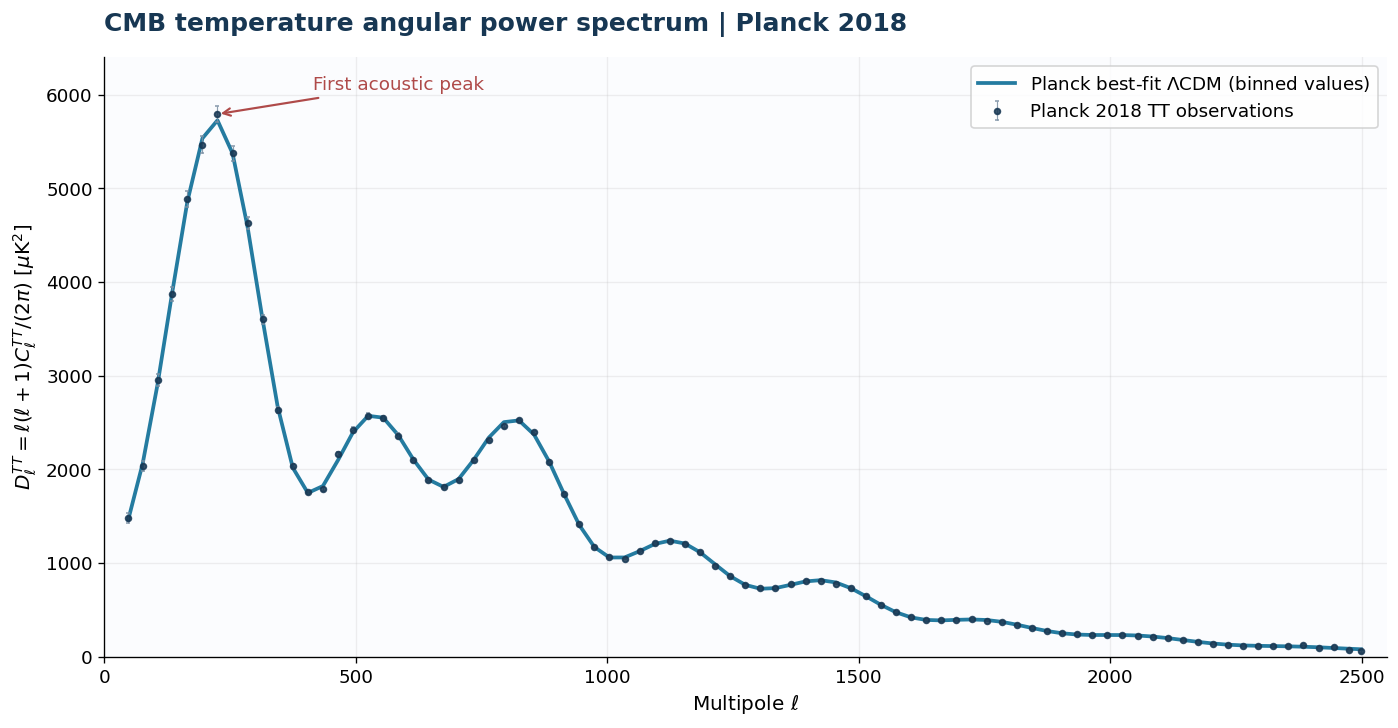

In [6]:
# 3. Figure 2 — Angular power spectrum from measured Planck 2018 TT data
fig, ax = plt.subplots(figsize=(11.8, 6.2))
ax.set_facecolor("#FBFCFE")
ax.plot(ell, D_TT_best, color=C_BLUE, lw=2.25,
        label=r"Planck best-fit $\Lambda$CDM (binned values)", zorder=2)
ax.errorbar(ell, D_TT, yerr=sigma_D, fmt="o", ms=3.5,
            elinewidth=0.7, capsize=1.3, alpha=0.85,
            color=C_NAVY, ecolor="#7B8FA3", label="Planck 2018 TT observations", zorder=3)
ax.set(xlim=(0, 2550), ylim=(0, 6400),
       xlabel=r"Multipole $\ell$", ylabel=r"$D_\ell^{TT}=\ell(\ell+1)C_\ell^{TT}/(2\pi)$ [$\mu$K$^2$]")
ax.set_title("CMB temperature angular power spectrum | Planck 2018", loc="left", pad=16, color=C_NAVY)
ax.grid(True, which="major")
ax.legend(loc="upper right", frameon=True, facecolor="white")
ax.annotate("First acoustic peak", xy=(225.16, 5793), xytext=(415, 6050),
            arrowprops=dict(arrowstyle="->", color=C_RED, lw=1.3), color=C_RED, fontsize=11)
fig.tight_layout()
plt.show()

### What are the acoustic peaks?

Before recombination, photons and baryons form a tightly coupled fluid. Gravity compresses overdense regions, while radiation pressure resists compression. This produces **acoustic oscillations**. Different wavelengths are observed at different oscillation phases at the time of last scattering.

A simplified oscillator intuition is

$$
\boxed{\delta_\gamma''+c_s^2k^2\delta_\gamma\simeq0},
\qquad \delta_\gamma\propto\cos(kr_s),
$$

where the sound horizon is $r_s(\eta)=\int^{\eta}c_s(\tilde\eta)d\tilde\eta$. This is a *teaching approximation* that omits gravity and baryon loading; the actual observed peaks arise from the full perturbation dynamics and projection.

**Baumann connection:** the first acoustic peak is near $\ell\simeq220$. The precise position depends on the sound horizon at last scattering and on how that distance projects onto the sky. The relative peak heights constrain matter and baryon content.

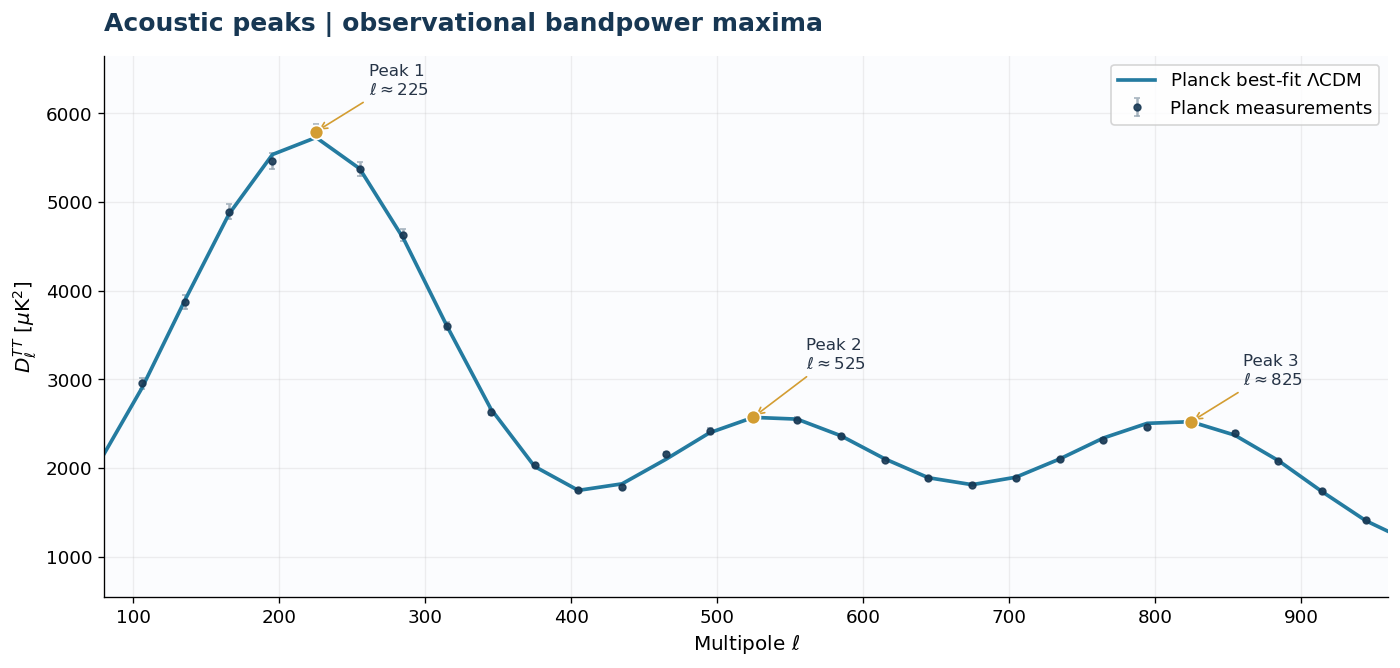

Approximate peak positions selected from the published *binned* data:
  Peak 1: ell ~ 225.2, D_ell ~  5793.4 microK^2, theta ~ 0.80 deg
  Peak 2: ell ~ 524.8, D_ell ~  2573.5 microK^2, theta ~ 0.34 deg
  Peak 3: ell ~ 824.7, D_ell ~  2521.9 microK^2, theta ~ 0.22 deg
Note: bin-centre maxima are NOT precision peak-location estimates.


In [9]:
# 4. Figure 3 — Zoom on the first three peaks (real binned observations)
regions = [(150, 310), (440, 635), (735, 915)]
peaks = []
for left, right in regions:
    mask = (ell >= left) & (ell <= right)
    indices = np.flatnonzero(mask)
    j = indices[np.argmax(D_TT[mask])]
    peaks.append((ell[j], D_TT[j]))

fig, ax = plt.subplots(figsize=(11.8, 5.7))
ax.set_facecolor("#FBFCFE")
ax.errorbar(ell, D_TT, yerr=sigma_D, fmt="o", ms=4, capsize=1.6,
            color=C_NAVY, ecolor="#9AA9B5", alpha=0.87, label="Planck measurements")
ax.plot(ell, D_TT_best, color=C_BLUE, lw=2.2, label=r"Planck best-fit $\Lambda$CDM")
for n, (x, y) in enumerate(peaks, start=1):
    ax.scatter([x], [y], s=70, color=C_GOLD, edgecolor="white", zorder=5)
    ax.annotate(f"Peak {n}\n$\\ell\\approx{x:.0f}$", xy=(x, y),
                xytext=(x+36, y+(420 if n != 2 else 550)),
                arrowprops=dict(arrowstyle="->", lw=1.0, color=C_GOLD),
                fontsize=10, color=C_DARK)
ax.set(xlim=(80, 960), ylim=(550, 6650), xlabel=r"Multipole $\ell$",
       ylabel=r"$D_\ell^{TT}$ [$\mu$K$^2$]")
ax.set_title("Acoustic peaks | observational bandpower maxima", color=C_NAVY, loc="left", pad=15)
ax.grid(True)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

print("Approximate peak positions selected from the published *binned* data:")
for i, (peak_ell, peak_D) in enumerate(peaks, start=1):
    print(f"  Peak {i}: ell ~ {peak_ell:5.1f}, D_ell ~ {peak_D:7.1f} microK^2, theta ~ {180/peak_ell:.2f} deg")
print("Note: bin-centre maxima are NOT precision peak-location estimates.")

## 5 · Origin of the fluctuations: inflation $\to$ temperature spectrum

Let $\mathcal R(\boldsymbol k)$ be the **primordial comoving curvature perturbation**, with dimensionless power spectrum $\mathcal P_{\mathcal R}(k)$. The multipole transfer function $\Delta_\ell^T(k)$ evolves the initial perturbations through the radiation–matter plasma and projects them onto the observed sky.

$$
\boxed{C_\ell^{\Theta\Theta}=
4\pi\int d\ln k\,\mathcal P_{\mathcal R}(k)\left|\Delta_\ell^T(k)\right|^2}.
$$

A frequently used parameterization of the initial scalar spectrum is

$$
\boxed{\mathcal P_{\mathcal R}(k)=A_s\left(\frac{k}{k_*}\right)^{n_s-1}}.
$$

- $A_s$ — amplitude of primordial curvature fluctuations.
- $n_s$ — scalar spectral index.
- $k_*$ — chosen pivot wavenumber.

**Physical chain:** quantum fluctuations in standard inflationary scenarios $\to$ primordial curvature perturbations $\to$ acoustic oscillations and gravitational effects $\to$ measured $C_\ell^{TT}$.

> **Do not conflate two different spectra:** $\mathcal P_{\mathcal R}(k)$ is a three-dimensional primordial power spectrum in wavenumber $k$, while $C_\ell$ is the angular spectrum of the observed two-dimensional sky. $\Delta_\ell^T(k)$ is the essential bridge. Computing it accurately requires a Boltzmann solver such as CLASS or CAMB; we have not fabricated one here.

## 6 · Physical checkpoints

**Q1.** If the angular spectrum has a large $D_{220}^{TT}$, does that mean the average CMB temperature is larger in every direction? Why not?

**Q2.** Why does a large $\ell$ correspond to smaller angular structures on the sky?

**Q3.** Why are the two expressions $\mathcal P_\mathcal R(k)$ and $C_\ell$ not interchangeable?

**Q4.** Is the first maximum of our binned points an exact measurement of the underlying peak location? *(Hint: finite bin widths.)*

---

### Key formulae to remember

$$
\boxed{\Theta(\hat{\boldsymbol n})=\delta T(\hat{\boldsymbol n})/\bar T_0}
$$

$$
\boxed{\Theta(\hat{\boldsymbol n})=\sum_{\ell m}a_{\ell m}Y_{\ell m}(\hat{\boldsymbol n})}
$$

$$
\boxed{D_\ell^{TT}=\frac{\ell(\ell+1)}{2\pi}C_\ell^{TT}}
$$

$$
\boxed{C_\ell^{\Theta\Theta}=4\pi\int d\ln k\,\mathcal P_\mathcal R(k)|\Delta_\ell^T(k)|^2}
$$

**Next:** inflation, scalar-field dynamics, comoving Hubble radius, then scalar and tensor perturbations.

## Scientific sources & reproducibility

- **ESA / Planck Collaboration (2018):** [Planck's view of the CMB](https://www.esa.int/ESA_Multimedia/Images/2018/07/Planck_s_view_of_the_cosmic_microwave_background2). *Published RGB visual product, not calibrated FITS pixel data.*
- **NASA/IPAC IRSA — Planck PR3:** [Observed TT spectrum, binned 2018 release](https://irsa.ipac.caltech.edu/data/Planck/release_3/ancillary-data/cosmoparams/COM_PowerSpect_CMB-TT-binned_R3.01.txt). Contains $\ell$, $D_\ell$, lower and upper errors, best-fit model bandpowers.
- **Planck Collaboration V (2020):** [CMB power spectra and likelihoods](https://www.aanda.org/articles/aa/full_html/2020/09/aa36386-19/aa36386-19.html), *Astronomy & Astrophysics*, **641**, A5.
- **Daniel Baumann:** *Cosmology*, Ch. 3, 6–7 (esp. §§ 6.1, 7.1, 7.2–7.5).

The notebook embeds the 83 TT bandpowers so plots work offline; only the ESA image needs a network connection to load. The source link remains available if it is not displayed. No synthetic sky map, theory fit, or Monte Carlo observational values are substituted for Planck measurements.